# iAmTime forecasting demo on financial data

[iAmTime](https://arxiv.org/abs/2603.22586) is a time-series foundation model that accepts **in-context examples**: completed (history → future) demonstrations passed together with the series to forecast. fev-bench has no finance task, so this notebook uses a dataset built with `build_finance_dataset.py`: daily trading data for current S&P 500 constituents, with an earnings calendar, market-calendar flags, market and macro covariates, and GICS sector / industry metadata. It keeps the three-part format of the other demos:

| Part | What you get |
|---|---|
| **Input card** | the exact array / dict shape passed to `predict_quantiles` |
| **Hero figure** | history → forecast fan (10–90 %) + median, observed future overlaid, and one **dashed reference line** = "what you would get without the feature" |
| **Honesty table** | the same comparison on many ticker-origin pairs: mean / median MASE, win rate, paired bootstrap CI |

**Targets.** Daily returns are close to unpredictable (a martingale), so every forecaster scores about the same on them; Section 1 shows that as a sanity check. The demos instead forecast quantities with real structure: **log trading volume** (`log_volume`) and **realised volatility** (`rv_gk`, annualised Garman–Klass volatility from daily OHLC).

| § | Task | Reference line | What it shows |
|---|---|---|---|
| 1 | Univariate forecasting of volume and volatility | random walk (last value) | zero-shot 20-day forecasts vs. the standard baselines; returns as a sanity check |
| 2 | Multivariate forecasting | univariate forecast | within one stock (volume, volatility, absolute return); across stocks grouped by **GICS industry** or by **k-means on return correlations**, against random groups |
| 3 | Covariates and what-if scenarios | forecast without covariates | market-calendar and **earnings-calendar** flags known in advance; market and macro covariates (VIX, index and sector returns, 10-year yield, yield curve, consumer sentiment); earnings-date and earnings-surprise scenarios |
| 4 | Forecasting with examples (ICL) | zero-shot from the same short context | **event-aligned examples**: the stock's own and its industry peers' past earnings windows; a cold start with peers only |

Earnings announcements play the role that promotions played in the retail demos: known in advance, with a large and repeatable effect on volume and volatility.

Checkpoint: [`anishsaha/iAmTime-base-forecast`](https://huggingface.co/anishsaha/iAmTime-base-forecast). Figures are saved to `docs/figures/` (relative to the notebook).

## Setup

Build the dataset first (network access needed for Yahoo Finance, Wikipedia and FRED), from the `notebooks` directory:

```bash
pip install -e "..[notebook]" yfinance lxml pyarrow
python build_finance_dataset.py --snapshot 2026-10-02 --start 2015-01-01 --out data/
```

The full build downloads about 500 tickers plus their earnings calendars and takes a while; downloads are cached in `data/cache/`, so an interrupted build resumes. The manifest `data/finance_sp500_<snapshot>_manifest.json` records the build and a data-quality report. Yahoo Finance data is for personal and research use: keep the parquet private (figures are fine to share).

In [1]:
import os
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.ticker import FuncFormatter
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

from build_finance_dataset import KNOWN_FUTURE, PAST_ONLY, load_finance
from iAmTime.pipeline import iAmTimePipeline

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=3, suppress=True)

In [2]:
if torch.cuda.is_available():
    DEVICE = "cuda"
    TORCH_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32
else:
    DEVICE = "cpu"
    TORCH_DTYPE = torch.float32

MODEL_ID = "anishsaha/iAmTime-base-forecast"

print(f"Device: {DEVICE}")
print(f"Dtype: {TORCH_DTYPE}")
print(f"Model: {MODEL_ID}")

Device: cpu
Dtype: torch.float32
Model: anishsaha/iAmTime-base-forecast


In [3]:
pipeline = iAmTimePipeline.from_pretrained(
    MODEL_ID,
    device_map=DEVICE,
    dtype=TORCH_DTYPE,
)
pipeline.model.eval()
print("Pipeline loaded successfully.")

Pipeline loaded successfully.


### Helpers: forecasts, evaluation, plots

Forecasts are scored with **MASE**: the mean absolute error of the median forecast divided by the in-sample mean absolute error of a one-step naive forecast on the context. Lower is better; a random walk scores close to 1 on returns. Each section ends with a **scorecard**: mean and median MASE, the win rate against a reference variant, and a paired bootstrap 95 % CI on the mean difference.

In [4]:
QUANTILE_LEVELS = [0.1, 0.5, 0.9]
COLORS = {"history": "#3f4652", "truth": "#23836b", "forecast": "#8f5fa2", "reference": "#d08c2e"}

FIG_DIR = Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"finance_{name}.png", dpi=130, bbox_inches="tight")

def predict(input_batch, horizon):
    quantiles, _ = pipeline.predict_quantiles(input_batch, prediction_length=horizon, quantile_levels=QUANTILE_LEVELS)
    return quantiles.detach().cpu().numpy() if isinstance(quantiles, torch.Tensor) else quantiles

def mase(history, truth, forecast, season):
    scale = np.mean(np.abs(history[season:] - history[:-season]))
    return float(np.mean(np.abs(truth - forecast)) / max(scale, 1e-6))

def seasonal_naive(history, horizon, season):
    return np.resize(history[-season:], horizon)

def scorecard(scores, reference, n_boot=2000, seed=0):
    # scores: DataFrame, one column per variant, one row per forecast, values = MASE.
    rng = np.random.default_rng(seed)
    n = len(scores)
    idx = rng.integers(0, n, size=(n_boot, n))
    ref = scores[reference].to_numpy()
    rows = []
    for name in scores.columns:
        s = scores[name].to_numpy()
        diff = s - ref
        mean_ci = np.percentile(s[idx].mean(axis=1), [2.5, 97.5])
        diff_ci = np.percentile(diff[idx].mean(axis=1), [2.5, 97.5])
        rows.append({
            "mean MASE": s.mean(), "mean 95% CI": f"[{mean_ci[0]:.3f}, {mean_ci[1]:.3f}]",
            "median MASE": np.median(s),
            "win rate vs ref": np.nan if name == reference else (s < ref).mean(),
            "Δ mean vs ref": diff.mean(), "Δ 95% CI": f"[{diff_ci[0]:.3f}, {diff_ci[1]:.3f}]",
        })
    table = pd.DataFrame(rows, index=scores.columns)
    table.index.name = f"reference: {reference}"
    return table.round(3)

def plot_ladder(scores, reference, title, name=None, n_boot=2000):
    # Horizontal bars of mean MASE with bootstrap CIs; the reference bar is grey.
    rng = np.random.default_rng(0)
    idx = rng.integers(0, len(scores), size=(n_boot, len(scores)))
    means = scores.mean()
    cis = np.stack([np.percentile(scores[c].to_numpy()[idx].mean(axis=1), [2.5, 97.5]) for c in scores.columns])
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(scores.columns) + 1.2))
    y = np.arange(len(scores.columns))[::-1]
    colors = ["#9a9a9a" if c == reference else COLORS["forecast"] for c in scores.columns]
    ax.barh(y, means, color=colors, height=0.6)
    ax.errorbar(means, y, xerr=[means - cis[:, 0], cis[:, 1] - means], fmt="none", ecolor="#333333", capsize=3, lw=1)
    ax.set_yticks(y, scores.columns)
    ax.set_xlabel(f"mean MASE over {len(scores)} forecasts (bootstrap 95% CI)")
    ax.set_title(title)
    ax.axvline(means[reference], color="#9a9a9a", lw=0.8, ls="--")
    plt.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()

def plot_forecast(ax, history_x, history, future_x, truth, quantiles, title, reference=None, reference_label=None, ylabel=None):
    ax.plot(history_x, history, color=COLORS["history"], lw=1.1, label="History")
    ax.plot(future_x, truth, color=COLORS["truth"], lw=1.3, label="Observed future")
    ax.fill_between(future_x, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.20, label="10-90% interval")
    ax.plot(future_x, quantiles[:, 1], color=COLORS["forecast"], lw=1.6, label="Median forecast")
    if reference is not None:
        ax.plot(future_x, reference, color=COLORS["reference"], lw=1.2, ls="--", label=reference_label)
    ax.axvline(future_x[0], color="#999999", lw=0.8, ls="--")
    ax.set_title(title)
    if ylabel:
        ax.set_ylabel(ylabel)

### Finance data

`load_finance` returns the same layout as the fev-bench datasets: one row per ticker, equal-length arrays per column, static metadata as scalars. Tickers listed after the start date have `NaN` before `first_valid`; Sections 1–4 use the **complete** tickers (history from the first year), and the cold-start case in 4d looks at the late entrants separately.

Column groups (see `finance_dataset_handoff.md` for the full reference):

- **targets**: `log_volume`, `rv_gk`, `abs_return`, `log_return` (and price columns);
- **known-future**: `earnings_day`, `earnings_reaction` (first session that can trade on the news, using the announcement time when Yahoo reports it), `earnings_window`, `days_to_earnings`, `opex`, `triple_witching`, `fomc`, `month_end`, `quarter_end`, `day_of_week`;
- **past-only**: `vix_close`, `spx_log_return`, `sector_etf_log_return`, `us10y_yield`, `yield_curve_10y2y`, `consumer_sentiment`, `news_sentiment` (empty unless a sentiment file was supplied), `eps_surprise_pct`.

In [5]:
SNAPSHOT = "2026-10-02"
DATA_PATH = os.environ.get("IAMTIME_FINANCE_DATA", f"data/finance_sp500_{SNAPSHOT}.parquet")

all_items = load_finance(DATA_PATH)
days = pd.DatetimeIndex(all_items["timestamp"].iloc[0])
complete_from = days[0] + pd.DateOffset(years=1)
items = all_items[all_items["first_valid"] <= complete_from].reset_index(drop=True)
late_items = all_items[all_items["first_valid"] > complete_from].reset_index(drop=True)
tickers = items["id"].tolist()
print(f"{len(all_items)} tickers in {DATA_PATH}; {len(items)} complete since {days[0].date()}, {len(late_items)} later entrants")
print(f"{days[0].date()} to {days[-1].date()} ({len(days)} trading days)")
print("Tickers per sector:", items["sector"].value_counts().to_dict())

def matrix(column, frame=items):
    return np.stack(frame[column].to_numpy())

log_volume, rv, abs_return, log_return = matrix("log_volume"), matrix("rv_gk"), matrix("abs_return"), matrix("log_return")
reaction = matrix("earnings_reaction")
has_earnings = reaction.sum(axis=1) > 0
print(f"Earnings reactions per ticker (median): {np.median(reaction.sum(axis=1)):.0f}; tickers without earnings data: {int((~has_earnings).sum())}")
industry = items["industry"].to_numpy()
sector = items["sector"].to_numpy()

def row_of(ticker):
    return tickers.index(ticker)

HORIZON = 20     # Trading days (about one month).
CONTEXT = 252    # Trading days (about one year).
origin = len(days) - HORIZON
future_days = days[origin:origin + HORIZON]

def score(values, row, o, forecast, context=CONTEXT):
    return mase(values[row, o - context:o], values[row, o:o + HORIZON], forecast, 1)

def finite_rows(values, o, context=CONTEXT):
    window = values[:, o - context:o + HORIZON]
    return np.flatnonzero(np.isfinite(window).all(axis=1))

499 tickers in data/finance_sp500_2026-10-02.parquet; 464 complete since 2015-01-02, 35 later entrants
2015-01-02 to 2026-10-02 (2955 trading days)
Tickers per sector: {'Financials': 74, 'Industrials': 71, 'Information Technology': 68, 'Health Care': 57, 'Consumer Discretionary': 44, 'Consumer Staples': 32, 'Utilities': 29, 'Real Estate': 28, 'Materials': 23, 'Energy': 20, 'Communication Services': 18}
Earnings reactions per ticker (median): 47; tickers without earnings data: 1


## 1. Univariate forecasting: volume and volatility

**Input card.** A two-dimensional array with shape `(batch, context)`:

```python
uni_input = log_volume[rows, origin - 252:origin]      # (3, 252): one year of daily log volume
quantiles, _ = pipeline.predict_quantiles(uni_input, prediction_length=20, quantile_levels=[0.1, 0.5, 0.9])
# quantiles: (3, 20, 3)
```

Three large stocks from different sectors, forecast for the last 20 trading days of the snapshot.

**How to read the figure.** Left: log volume; right: realised volatility. Grey = the last 60 days of the context; purple = median forecast with the 10–90 % band; green = what happened; **dashed orange = random walk** (the last value carried forward). Earnings reaction days are marked with red ticks.

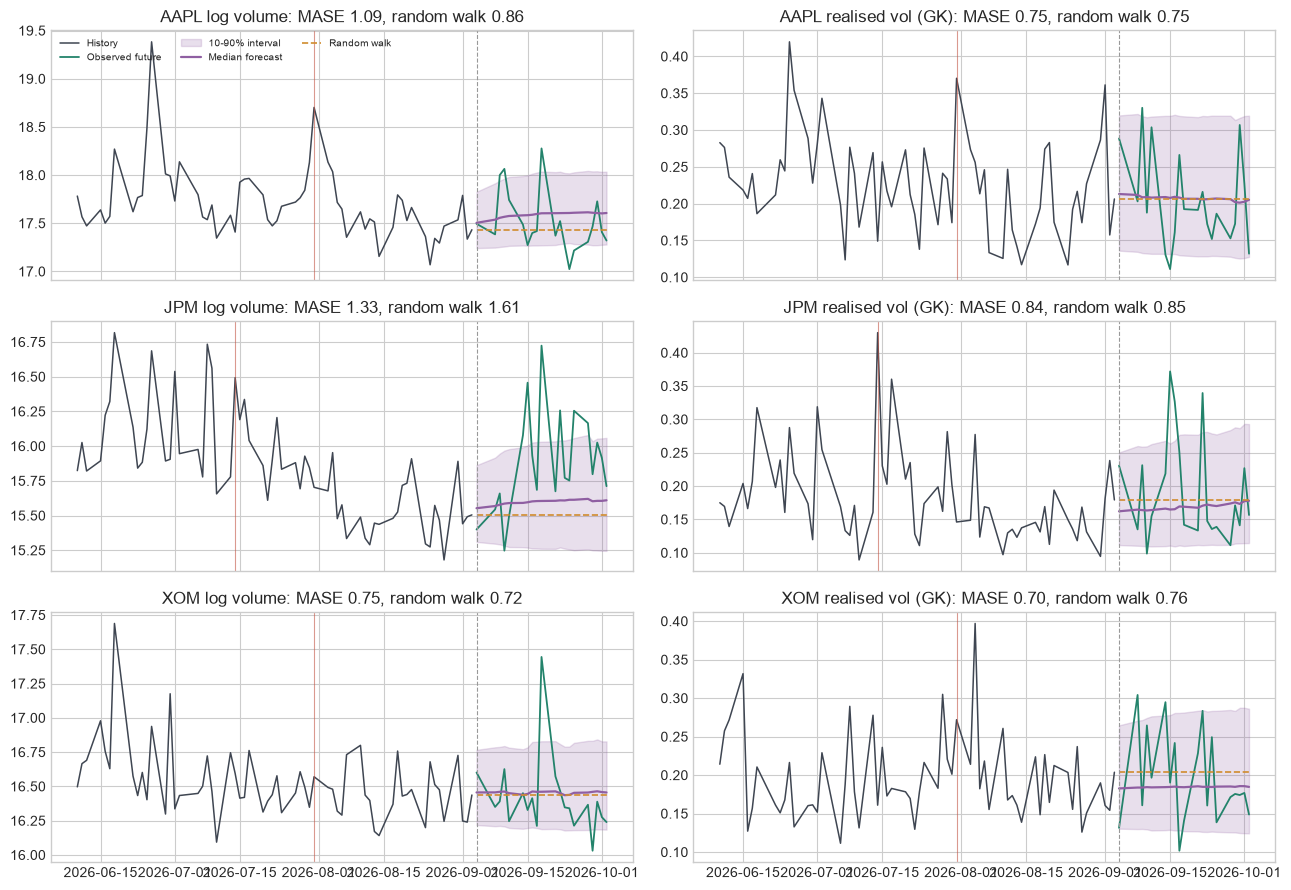

In [6]:
UNIVARIATE_TICKERS = [t for t in ["AAPL", "JPM", "XOM"] if t in tickers] or tickers[:3]
rows = [row_of(t) for t in UNIVARIATE_TICKERS]
volume_q = predict(log_volume[rows, origin - CONTEXT:origin], HORIZON)
rv_q = predict(rv[rows, origin - CONTEXT:origin], HORIZON)

fig, axes = plt.subplots(len(rows), 2, figsize=(13, 3.0 * len(rows)), sharex=True)
for k, row in enumerate(rows):
    for ax, values, quantiles, label in [(axes[k, 0], log_volume, volume_q[k], "log volume"), (axes[k, 1], rv, rv_q[k], "realised vol (GK)")]:
        context = values[row, origin - CONTEXT:origin]
        truth = values[row, origin:origin + HORIZON]
        naive = np.full(HORIZON, context[-1])
        plot_forecast(ax, days[origin - 60:origin], context[-60:], future_days, truth, quantiles,
                      f"{tickers[row]} {label}: MASE {score(values, row, origin, quantiles[:, 1]):.2f}, random walk {score(values, row, origin, naive):.2f}",
                      reference=naive, reference_label="Random walk")
        for d in np.flatnonzero(reaction[row, origin - 60:origin + HORIZON]):
            ax.axvline(days[origin - 60 + d], color="#c25645", lw=0.8, alpha=0.6)
axes[0, 0].legend(ncol=3, frameon=False, loc="upper left", fontsize=7)
plt.tight_layout()
savefig(fig, "01_univariate")
plt.show()

### 1b. Scorecard: iAmTime vs. simple baselines

128 random (ticker, origin) pairs with 8 monthly origins over the last year of the snapshot. Baselines: random walk (last value), the 20-day trailing mean (the usual volume benchmark) and the weekly seasonal naive (same weekday last week). The last table runs the same comparison on **daily returns**, where nothing should beat a zero forecast by much.

In [7]:
rng = np.random.default_rng(0)
score_origins = [len(days) - HORIZON - k * 21 for k in range(8)]
score_pairs = [(r, o) for o in score_origins for r in finite_rows(log_volume, o)]
score_pairs = [score_pairs[k] for k in rng.choice(len(score_pairs), size=min(128, len(score_pairs)), replace=False)]

def baseline_scores(values, pairs):
    quantiles = predict(np.stack([values[r, o - CONTEXT:o] for r, o in pairs]), HORIZON)
    return pd.DataFrame({
        "random walk": [score(values, r, o, np.full(HORIZON, values[r, o - 1])) for r, o in pairs],
        "20-day mean": [score(values, r, o, np.full(HORIZON, values[r, o - 20:o].mean())) for r, o in pairs],
        "seasonal naive (last week)": [score(values, r, o, seasonal_naive(values[r, o - CONTEXT:o], HORIZON, 5)) for r, o in pairs],
        "iAmTime zero-shot": [score(values, r, o, q[:, 1]) for (r, o), q in zip(pairs, quantiles)],
    })

print("log volume")
display(scorecard(baseline_scores(log_volume, score_pairs), reference="random walk"))
print("realised volatility (Garman-Klass)")
display(scorecard(baseline_scores(rv, [p for p in score_pairs if np.isfinite(rv[p[0], p[1] - CONTEXT:p[1] + HORIZON]).all()]), reference="random walk"))

return_pairs = [p for p in score_pairs if np.isfinite(log_return[p[0], p[1] - CONTEXT:p[1] + HORIZON]).all()]
return_q = predict(np.stack([log_return[r, o - CONTEXT:o] for r, o in return_pairs]), HORIZON)
print("daily log returns (sanity check)")
scorecard(pd.DataFrame({
    "zero forecast": [score(log_return, r, o, np.zeros(HORIZON)) for r, o in return_pairs],
    "iAmTime zero-shot": [score(log_return, r, o, q[:, 1]) for (r, o), q in zip(return_pairs, return_q)],
}), reference="zero forecast")

log volume


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: random walk,,,,,,
random walk,1.285,"[1.192, 1.388]",1.128,NaN,0.000,"[0.000, 0.000]"
20-day mean,1.074,"[1.014, 1.139]",1.015,0.609,-0.211,"[-0.308, -0.122]"
seasonal naive (last week),1.319,"[1.248, 1.396]",1.253,0.430,0.034,"[-0.055, 0.118]"
iAmTime zero-shot,1.036,"[0.978, 1.097]",0.978,0.648,-0.249,"[-0.345, -0.168]"


realised volatility (Garman-Klass)


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: random walk,,,,,,
random walk,1.131,"[1.028, 1.244]",1.009,NaN,0.000,"[0.000, 0.000]"
20-day mean,0.845,"[0.797, 0.894]",0.790,0.695,-0.286,"[-0.396, -0.189]"
seasonal naive (last week),1.159,"[1.095, 1.227]",1.101,0.414,0.028,"[-0.068, 0.123]"
iAmTime zero-shot,0.842,"[0.793, 0.892]",0.779,0.695,-0.289,"[-0.395, -0.197]"


daily log returns (sanity check)


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: zero forecast,,,,,,
zero forecast,0.769,"[0.734, 0.805]",0.719,NaN,0.000,"[0.000, 0.000]"
iAmTime zero-shot,0.773,"[0.738, 0.809]",0.720,0.398,0.004,"[0.001, 0.007]"


## 2. Multivariate forecasting

Two ways to form a multivariate input:

- **within one stock**: log volume, realised volatility and absolute return move together (busy days are volatile days);
- **across stocks**: three stocks whose volumes share a common driver, grouped either by **GICS industry** (the analyst's grouping) or by **k-means clusters of return correlations** (a data-driven grouping), against **random triples** as a control.

**Input card.** A three-dimensional array with shape `(batch, variates, context)`:

```python
within = np.stack([log_volume[row], rv[row], abs_return[row]])[None, :, origin - 252:origin]   # (1, 3, 252)
across = log_volume[[row_a, row_b, row_c]][None, :, origin - 252:origin]                       # (1, 3, 252)
```

### 2a. Grouping stocks: GICS industry vs. k-means

k-means runs on z-normalised daily returns over the first three years of the data (only past data relative to every forecast origin used below), with as many clusters as there are sectors. The adjusted Rand index measures how closely the data-driven clusters reproduce the GICS sectors (1 = identical, 0 = chance).

In [8]:
TRAIN_DAYS = slice(1, 3 * 252)   # Skip the first day (no return); every forecast origin below is later.
returns_train = np.nan_to_num(log_return[:, TRAIN_DAYS])
z_returns = (returns_train - returns_train.mean(axis=1, keepdims=True)) / returns_train.std(axis=1, keepdims=True).clip(min=1e-9)
num_clusters = len(set(sector))
kmeans = KMeans(n_clusters=num_clusters, n_init=10, random_state=0).fit(z_returns)
cluster = kmeans.labels_
print(f"{num_clusters} k-means clusters; adjusted Rand index vs. GICS sectors: {adjusted_rand_score(sector, cluster):.2f}")
summary = pd.DataFrame({"sector": sector, "cluster": cluster}).groupby("cluster")["sector"].agg(lambda s: f"{len(s)} stocks, mostly {s.value_counts().index[0]} ({s.value_counts().iloc[0]})")
print(summary.to_string())

def triples_by(labels, count, rng):
    groups = [np.flatnonzero(labels == g) for g in np.unique(labels)]
    candidates = [tuple(c) for g in groups if len(g) >= 3 for c in combinations(g, 3)]
    return [candidates[k] for k in rng.choice(len(candidates), size=min(count, len(candidates)), replace=False)]

11 k-means clusters; adjusted Rand index vs. GICS sectors: 0.47
cluster
0                  8 stocks, mostly Industrials (4)
1                 55 stocks, mostly Financials (54)
2                18 stocks, mostly Health Care (14)
3                73 stocks, mostly Industrials (14)
4                  50 stocks, mostly Utilities (28)
5     58 stocks, mostly Information Technology (53)
6     25 stocks, mostly Consumer Discretionary (18)
7                83 stocks, mostly Industrials (46)
8           25 stocks, mostly Consumer Staples (21)
9                47 stocks, mostly Health Care (41)
10                    22 stocks, mostly Energy (18)


### 2b. Hero: one industry triple

The three largest-volume stocks of one industry, last 20 days. Solid purple = joint forecast; **dashed orange = each stock forecast on its own**.

Health Care Equipment: BSX, ABT, MDT; correlation of log volume:
[[1.   0.58 0.54]
 [0.58 1.   0.57]
 [0.54 0.57 1.  ]]


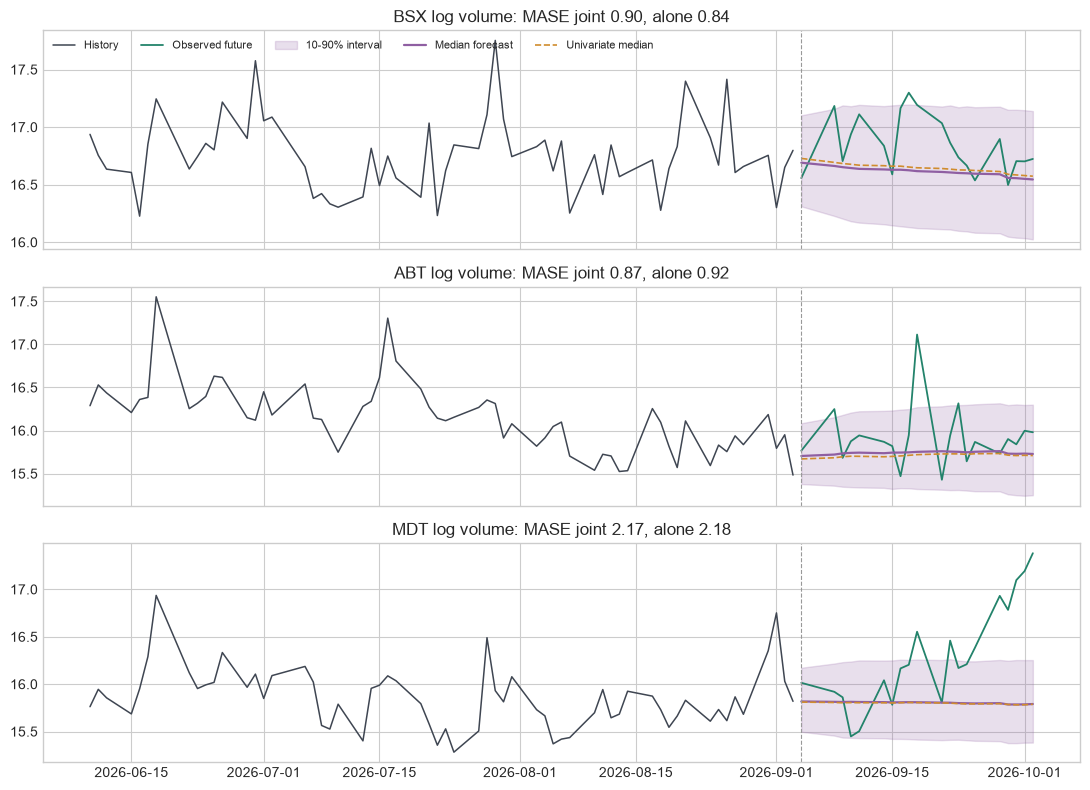

In [9]:
industry_sizes = pd.Series(industry).value_counts()
HERO_INDUSTRY = industry_sizes.index[0]
members = np.flatnonzero(industry == HERO_INDUSTRY)
hero_triple = members[np.argsort(-np.nanmean(log_volume[members, origin - CONTEXT:origin], axis=1))[:3]]
triple_context = log_volume[hero_triple, origin - CONTEXT:origin]
print(f"{HERO_INDUSTRY}: {', '.join(tickers[r] for r in hero_triple)}; correlation of log volume:")
print(np.corrcoef(triple_context).round(2))
joint_q = predict(triple_context[None], HORIZON)[0]
single_q = predict(triple_context, HORIZON)

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, row, joint, single in zip(axes, hero_triple, joint_q, single_q):
    truth = log_volume[row, origin:origin + HORIZON]
    plot_forecast(ax, days[origin - 60:origin], log_volume[row, origin - 60:origin], future_days, truth, joint,
                  f"{tickers[row]} log volume: MASE joint {score(log_volume, row, origin, joint[:, 1]):.2f}, alone {score(log_volume, row, origin, single[:, 1]):.2f}",
                  reference=single[:, 1], reference_label="Univariate median")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "02_industry_triple")
plt.show()

### 2c. Scorecard: which groupings help?

For each construction, the mean MASE of the joint forecast minus that of the separate forecasts (negative = joint is better), on 4 origins over the last year:

- **within-ticker**: (log volume, realised vol, absolute return) of one stock, scored on log volume;
- **same industry**, **same k-means cluster**, **random stocks**: log-volume triples, scored on all three members.

In [10]:
rng = np.random.default_rng(1)
group_origins = [len(days) - HORIZON - k * 63 for k in range(4)]

def joint_vs_separate(blocks, scored_variates):
    # blocks: (n, variates, CONTEXT + HORIZON) windows; score the given variates of each block.
    contexts, truths = blocks[:, :, :CONTEXT], blocks[:, :, CONTEXT:]
    joint = predict(contexts, HORIZON)
    separate = predict(contexts.reshape(-1, CONTEXT), HORIZON).reshape(joint.shape)
    rows = []
    for b in range(len(blocks)):
        for v in scored_variates:
            rows.append({"separate": mase(contexts[b, v], truths[b, v], separate[b, v, :, 1], 1),
                         "joint": mase(contexts[b, v], truths[b, v], joint[b, v, :, 1], 1)})
    return pd.DataFrame(rows)

def windows(values_list, rows_, o):
    return np.stack([v[r, o - CONTEXT:o + HORIZON] for v, r in zip(values_list, rows_)])

constructions = {}
within_blocks = [windows([log_volume, rv, abs_return], [r, r, r], o) for o in group_origins for r in rng.choice(len(tickers), size=16, replace=False)]
constructions["within-ticker (volume, vol, |return|)"] = (within_blocks, [0])
for name, labels in [("same industry", industry), ("same k-means cluster", cluster), ("random stocks", rng.permutation(np.repeat(np.arange(len(tickers) // 3 + 1), 3)[:len(tickers)]))]:
    blocks = [windows([log_volume] * 3, list(t), o) for o in group_origins for t in triples_by(labels, 16, rng)]
    constructions[name] = (blocks, [0, 1, 2])

rows_out = []
for name, (blocks, scored) in constructions.items():
    blocks = np.stack([b for b in blocks if np.isfinite(b).all()])
    result = joint_vs_separate(blocks, scored)
    diff = (result["joint"] - result["separate"]).to_numpy()
    boot = np.percentile(diff[np.random.default_rng(0).integers(0, len(diff), size=(2000, len(diff)))].mean(axis=1), [2.5, 97.5])
    rows_out.append({"construction": name, "forecasts": len(result), "separate MASE": result["separate"].mean(),
                     "joint MASE": result["joint"].mean(), "joint win rate": (diff < 0).mean(),
                     "Δ mean (joint − separate)": diff.mean(), "Δ 95% CI": f"[{boot[0]:.3f}, {boot[1]:.3f}]"})
pd.DataFrame(rows_out).set_index("construction").round(3)

,forecasts,separate MASE,joint MASE,joint win rate,Δ mean (joint − separate),Δ 95% CI
construction,,,,,,
"within-ticker (volume, vol, |return|)",63,1.061,1.047,0.667,-0.014,"[-0.024, -0.005]"
same industry,192,1.068,1.059,0.589,-0.008,"[-0.016, -0.001]"
same k-means cluster,192,1.050,1.041,0.635,-0.008,"[-0.014, -0.003]"
random stocks,192,1.093,1.087,0.625,-0.006,"[-0.012, -0.000]"


## 3. Covariates: calendars, earnings and the market

**Known-future covariates** are calendar facts published in advance: option expiries (`opex`, `triple_witching`), FOMC decision days, month and quarter ends, the weekday, and the **earnings calendar** (`earnings_day`, `earnings_reaction`, `earnings_window`, `days_to_earnings`; companies confirm the date weeks ahead). **Past-only covariates** are market and macro series whose future is unknown: VIX, S&P 500 and sector-ETF returns, the 10-year yield, the 10y–2y curve and consumer sentiment (each lagged to its publication time).

**Input card.** A dictionary per stock:

```python
{
    "target": log_volume[row, origin - 252:origin],                                        # (252,)
    "past_covariates":   {"opex": ..., "earnings_reaction": ..., "vix_close": ..., ...},   # each (252,)
    "future_covariates": {"opex": ..., "earnings_reaction": ..., ...},                     # known-future only, each (20,)
}
```

**How to read the figure.** A stock whose next earnings reaction falls inside the 20-day horizon. Solid = forecast with the calendar covariates, **dashed = without**. Below: the earnings reaction days (red), option expiries (blue) and FOMC days (grey).

Past-only covariates with data: ['vix_close', 'spx_log_return', 'sector_etf_log_return', 'us10y_yield', 'yield_curve_10y2y', 'consumer_sentiment']


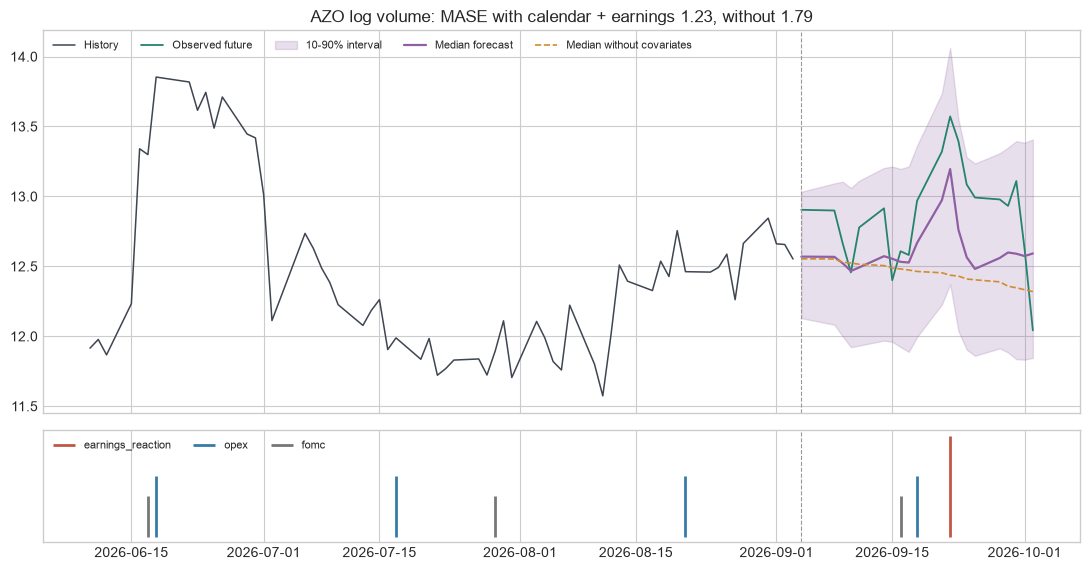

In [11]:
CALENDAR = ["opex", "triple_witching", "fomc", "month_end", "quarter_end", "day_of_week"]
EARNINGS = ["earnings_day", "earnings_reaction", "earnings_window", "days_to_earnings"]
MARKET = [c for c in ["vix_close", "spx_log_return", "sector_etf_log_return", "us10y_yield", "yield_curve_10y2y", "consumer_sentiment", "news_sentiment"]
          if np.isfinite(matrix(c)).any()]
print("Past-only covariates with data:", MARKET)
column_cache = {c: matrix(c) for c in CALENDAR + EARNINGS + MARKET + ["eps_surprise_pct"]}

def covariate_input(row, o, target=log_volume, known=(), past=(), override=None):
    override = override or {}
    def series(name):
        return override.get(name, column_cache[name][row])
    item = {"target": target[row, o - CONTEXT:o]}
    if known or past:
        item["past_covariates"] = {c: np.nan_to_num(series(c)[o - CONTEXT:o]) if c in known else series(c)[o - CONTEXT:o] for c in [*known, *past]}
    if known:
        item["future_covariates"] = {c: series(c)[o:o + HORIZON] for c in known}
    return item

# Hero: the first complete stock (in the Section 1 order) with an earnings reaction 5-15 days into the last horizon.
candidates = [r for r in rows + list(range(len(tickers))) if reaction[r, origin + 5:origin + 15].any()]
hero_row = candidates[0] if candidates else rows[0]
with_q, without_q = predict([covariate_input(hero_row, origin, known=CALENDAR + EARNINGS), covariate_input(hero_row, origin)], HORIZON)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.8), sharex=True, gridspec_kw={"height_ratios": [2.4, 0.7]})
truth = log_volume[hero_row, origin:origin + HORIZON]
plot_forecast(axes[0], days[origin - 60:origin], log_volume[hero_row, origin - 60:origin], future_days, truth, with_q,
              f"{tickers[hero_row]} log volume: MASE with calendar + earnings {score(log_volume, hero_row, origin, with_q[:, 1]):.2f}, "
              f"without {score(log_volume, hero_row, origin, without_q[:, 1]):.2f}",
              reference=without_q[:, 1], reference_label="Median without covariates")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
window = slice(origin - 60, origin + HORIZON)
for name, color, height in [("earnings_reaction", "#c25645", 1.0), ("opex", "#377ca8", 0.6), ("fomc", "#777777", 0.4)]:
    flags = column_cache[name][hero_row, window] > 0
    axes[1].vlines(days[window][flags], 0, height, color=color, lw=2, label=name)
axes[1].axvline(days[origin], color="#999999", lw=0.8, ls="--")
axes[1].set_yticks([])
axes[1].legend(ncol=3, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "03_calendar_covariates")
plt.show()

### 3a. Scorecard: which covariates matter?

The 128 ticker-origin pairs of 1b, with four inputs: no covariates; the market calendar; the market calendar plus the earnings calendar; and all of these plus the past-only market and macro series. The second table restricts the comparison to the pairs whose horizon contains an earnings reaction day, where the earnings calendar should matter most.

In [12]:
covariate_variants = {
    "no covariates": dict(),
    "market calendar": dict(known=CALENDAR),
    "calendar + earnings": dict(known=CALENDAR + EARNINGS),
    "calendar + earnings + market/macro (past-only)": dict(known=CALENDAR + EARNINGS, past=MARKET),
}
covariate_scores = pd.DataFrame({
    name: [score(log_volume, r, o, q[:, 1]) for (r, o), q in zip(score_pairs, predict([covariate_input(r, o, **kw) for r, o in score_pairs], HORIZON))]
    for name, kw in covariate_variants.items()
})
display(scorecard(covariate_scores, reference="no covariates"))
with_event = np.array([reaction[r, o:o + HORIZON].any() for r, o in score_pairs])
print(f"Pairs with an earnings reaction in the horizon: {with_event.sum()} of {len(score_pairs)}")
scorecard(covariate_scores[with_event].reset_index(drop=True), reference="no covariates")

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: no covariates,,,,,,
no covariates,1.036,"[0.978, 1.097]",0.978,NaN,0.000,"[0.000, 0.000]"
market calendar,0.995,"[0.941, 1.052]",0.966,0.695,-0.041,"[-0.057, -0.026]"
calendar + earnings,0.957,"[0.905, 1.015]",0.894,0.734,-0.079,"[-0.104, -0.056]"
calendar + earnings + market/macro (past-only),0.967,"[0.915, 1.025]",0.916,0.750,-0.069,"[-0.095, -0.047]"


Pairs with an earnings reaction in the horizon: 38 of 128


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: no covariates,,,,,,
no covariates,1.104,"[1.003, 1.221]",0.995,NaN,0.000,"[0.000, 0.000]"
market calendar,1.042,"[0.948, 1.151]",0.990,0.737,-0.062,"[-0.094, -0.031]"
calendar + earnings,0.921,"[0.833, 1.026]",0.887,0.895,-0.182,"[-0.245, -0.134]"
calendar + earnings + market/macro (past-only),0.925,"[0.839, 1.021]",0.885,0.947,-0.179,"[-0.245, -0.130]"


### 3b. What-if: moving the earnings date

Because known-future covariates are inputs, a different calendar is just another row in the batch. For the hero stock, the earnings date in the horizon is moved 5 trading days earlier or later, or removed, and the four earnings columns are recomputed for each scenario. Only the actual date has an observed outcome.

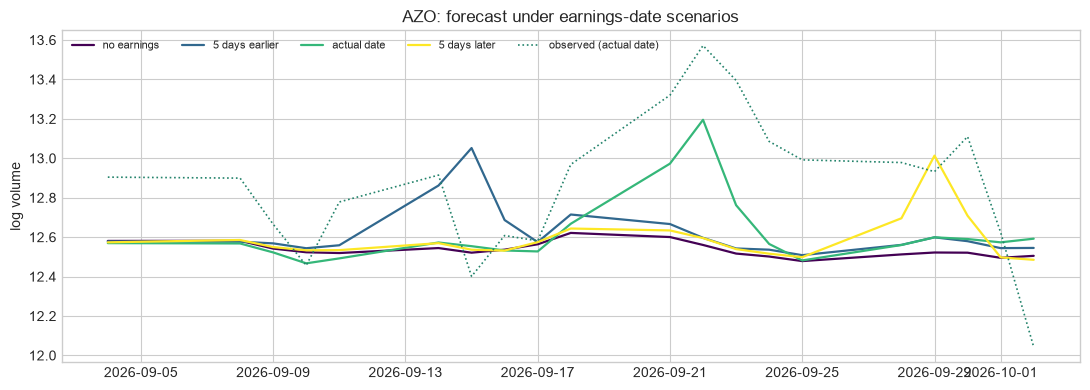

In [13]:
def earnings_scenario(row, shift, max_ahead=30):
    # Earnings columns with the in-horizon announcement moved by `shift` trading days (None = removed).
    out = {c: column_cache[c][row].copy() for c in EARNINGS}
    h = slice(origin, origin + HORIZON)
    actual = np.flatnonzero(column_cache["earnings_day"][row, h])
    actual_reaction = np.flatnonzero(column_cache["earnings_reaction"][row, h])
    lag = int(actual_reaction[0] - actual[0]) if len(actual) and len(actual_reaction) else 0
    for c in ("earnings_day", "earnings_reaction", "earnings_window"):
        out[c][h] = 0
    countdown = slice(origin - max_ahead, origin + HORIZON)     # the context's last weeks also count down to it
    out["days_to_earnings"][countdown] = max_ahead
    if shift is not None and len(actual):
        day = origin + int(np.clip(actual[0] + shift, 0, HORIZON - 1))
        out["earnings_day"][day] = 1
        if day + lag < origin + HORIZON:
            out["earnings_reaction"][day + lag] = 1
        out["earnings_window"][max(origin, day - 1):min(origin + HORIZON, day + 2)] = 1
        t = np.arange(origin - max_ahead, day + 1)
        out["days_to_earnings"][t] = np.minimum(day - t, max_ahead)
    return out

SHIFTS = {"no earnings": None, "5 days earlier": -5, "actual date": 0, "5 days later": 5}
scenario_q = predict([covariate_input(hero_row, origin, known=CALENDAR + EARNINGS, override=earnings_scenario(hero_row, s)) for s in SHIFTS.values()], HORIZON)

fig, ax = plt.subplots(figsize=(11, 4))
cmap = plt.get_cmap("viridis")
for k, (name, q) in enumerate(zip(SHIFTS, scenario_q)):
    ax.plot(future_days, q[:, 1], color=cmap(k / (len(SHIFTS) - 1)), lw=1.6, label=name)
ax.plot(future_days, log_volume[hero_row, origin:origin + HORIZON], color=COLORS["truth"], lw=1.2, ls=":", label="observed (actual date)")
ax.set_ylabel("log volume")
ax.set_title(f"{tickers[hero_row]}: forecast under earnings-date scenarios")
ax.legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "03_earnings_scenarios")
plt.show()

### 3c. Dose–response: earnings surprise vs. volume

How much does the size of the earnings surprise move volume on the reaction day? The surprise is only known once the market reacts, so it is a **past-only** covariate in the dataset; in a scenario it can be supplied as an assumed future value ("what if the company beats by 10 %?").

- x-axis: the assumed absolute EPS surprise on the next reaction day;
- y-axis: the predicted log-volume increase on that day relative to a 0 % surprise;
- dashed line: the historical relationship, a regression of the abnormal log volume on reaction days (relative to the 20 days before) on the absolute surprise, pooled over all stocks' announcements before the forecast origin.

20594 historical announcements; abnormal log volume ≈ 0.84 + 0.0011 × |surprise %|
 |surprise| %  predicted change in log volume
            0                           0.000
            2                           0.142
            5                           0.171
           10                           0.189
           20                           0.203
           40                           0.215


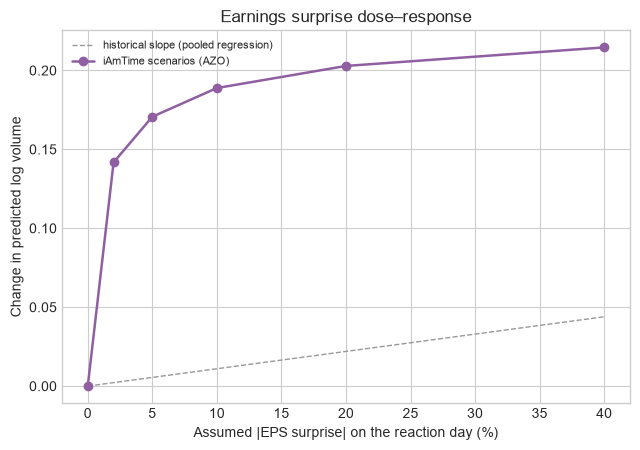

In [14]:
SURPRISES = [0, 2, 5, 10, 20, 40]
hero_reaction = np.flatnonzero(column_cache["earnings_reaction"][hero_row, origin:origin + HORIZON])
surprise_day = origin + (int(hero_reaction[0]) if len(hero_reaction) else HORIZON // 2)

def surprise_override(value):
    series = column_cache["eps_surprise_pct"][hero_row].copy()
    series[origin:] = 0
    series[surprise_day] = value
    return {"eps_surprise_pct": series}

dose_q = predict([covariate_input(hero_row, origin, known=CALENDAR + EARNINGS + ["eps_surprise_pct"], override=surprise_override(s)) for s in SURPRISES], HORIZON)
step = surprise_day - origin
response = [q[step, 1] - dose_q[0][step, 1] for q in dose_q]

# Historical relationship, pooled over announcements before the origin.
events = [(r, d) for r in range(len(tickers)) for d in np.flatnonzero(reaction[r, 21:origin]) + 21]
abnormal = np.array([log_volume[r, d] - np.nanmean(log_volume[r, d - 20:d]) for r, d in events])
abs_surprise = np.array([abs(column_cache["eps_surprise_pct"][r, d]) for r, d in events])
keep = np.isfinite(abnormal) & (abs_surprise > 0) & (abs_surprise < 100)
slope, intercept = np.polyfit(abs_surprise[keep], abnormal[keep], 1) if keep.sum() > 10 else (np.nan, np.nan)
print(f"{keep.sum()} historical announcements; abnormal log volume ≈ {intercept:.2f} + {slope:.4f} × |surprise %|")
print(pd.DataFrame({"|surprise| %": SURPRISES, "predicted change in log volume": np.round(response, 3)}).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.plot(SURPRISES, [slope * s for s in SURPRISES], color="#999999", lw=1.0, ls="--", label="historical slope (pooled regression)")
ax.plot(SURPRISES, response, "o-", color=COLORS["forecast"], lw=1.8, label=f"iAmTime scenarios ({tickers[hero_row]})")
ax.set_xlabel("Assumed |EPS surprise| on the reaction day (%)")
ax.set_ylabel("Change in predicted log volume")
ax.set_title("Earnings surprise dose–response")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
savefig(fig, "03_surprise_dose_response")
plt.show()

## 4. Forecasting with examples: event-aligned earnings windows

The full ICL input supplies completed **support examples** before the query. Each example has a target history and its observed future; the model treats them as demonstrations, without fine-tuning.

**Input card.**

```python
{
    "example_target_histories": [hist_1, ..., hist_k],   # each (40,)  completed demonstrations
    "example_target_futures":   [fut_1,  ..., fut_k],    # each (20,)
    "query_target_history":     hist_q,                  # (40,)       the stock to forecast
}
```

**Design.** Each query is a stock a few days (`lead` = 2–15 trading days) before an earnings reaction day, so the reaction falls inside the 20-day horizon. The query sees only its last **40 trading days**, which normally do not contain the previous announcement (about 63 days earlier), and **no covariates**: the examples are the only source of information that an earnings day is coming. Examples are **event-aligned**: windows with the same `lead` before earlier reaction days, so each example's future contains its earnings spike at the same position as the query's. They come from

- the stock's **own** earlier announcements (most recent first), and
- **industry peers**' most recent announcements (same GICS industry, else same sector).

Every example window ends before the query's forecast origin (no leakage).

| § | Question | Format |
|---|---|---|
| 4a | What does one forecast look like? | one query with its own last 4 announcements |
| 4b | What does the model actually see? | prompt-anatomy figure |
| 4c | Do examples help, and which ones? | scorecard on 256 forecasts + ladder with non-aligned windows and a shuffled-futures **control** |
| 4d | Cold start | 20 days of history, peers only; and the real late entrants |
| 4e | How does the error change with the number of examples? | k-shot curve, k = 0 to 12 |

In [15]:
ICL_CONTEXT = 40
reaction_days = [np.flatnonzero(reaction[r]) for r in range(len(tickers))]

def aligned_windows(row, before, lead, count, context=ICL_CONTEXT):
    # Example origins e = d - lead for earlier reaction days d of `row`, with the example future ending before `before`.
    ends = [d - lead for d in reaction_days[row][::-1] if d - lead + HORIZON <= before and d - lead - context >= 0]
    ends = [e for e in ends if np.isfinite(log_volume[row, e - context:e + HORIZON]).all()]
    return [(row, e) for e in ends[:count]]

def peers(row):
    same = np.flatnonzero((industry == industry[row]) & has_earnings)
    if len(same) <= 1:
        same = np.flatnonzero((sector == sector[row]) & has_earnings)
    return [p for p in same if p != row]

def peer_windows(row, before, lead, count, context=ICL_CONTEXT):
    found = [aligned_windows(p, before, lead, 1, context) for p in peers(row)]
    found = sorted([w[0] for w in found if w], key=lambda pe: -pe[1])     # most recent announcements first
    return found[:count]

def random_windows(row, before, count, context=ICL_CONTEXT):
    ends = np.arange(context, before - HORIZON + 1)
    picks = np.random.default_rng(1000 * row + before).choice(ends, size=count, replace=False)
    return [(row, int(e)) for e in picks]

def make_example_input(row, o, sources, context=ICL_CONTEXT, example_context=None, shuffle_futures=False):
    example_context = example_context or context
    query = log_volume[row, o - context:o]
    if not sources:
        return {"query_target_history": query}
    futures = [log_volume[r, e:e + HORIZON] for r, e in sources]
    if shuffle_futures:
        futures = futures[1:] + futures[:1]   # Every history gets another example's future.
    return {
        "example_target_histories": [log_volume[r, e - example_context:e] for r, e in sources],
        "example_target_futures": futures,
        "query_target_history": query,
    }

def icl_score(row, o, forecast, context=ICL_CONTEXT):
    return score(log_volume, row, o, forecast, context)

# Event queries over the last three years: (row, origin, lead) with the reaction inside the horizon.
rng = np.random.default_rng(2)
first_eval = len(days) - 3 * 252
event_queries = []
for r in range(len(tickers)):
    for d in reaction_days[r]:
        lead = int(rng.integers(2, 16))
        o = d - lead
        if first_eval <= o <= len(days) - HORIZON and np.isfinite(log_volume[r, o - ICL_CONTEXT:o + HORIZON]).all() \
                and len(aligned_windows(r, o, lead, 4)) == 4 and len(peer_windows(r, o, lead, 5)) >= 3:
            event_queries.append((r, o, lead))
event_queries = [event_queries[k] for k in rng.choice(len(event_queries), size=min(256, len(event_queries)), replace=False)]
print(f"{len(event_queries)} event-aligned queries from {days[first_eval].date()}")

256 event-aligned queries from 2023-09-28


### 4a. One query and its own past announcements

The query is the first stock of Section 1 (or the first stock with enough earnings history) 10 trading days before its most recent earnings reaction. The examples are the same stock's 4 previous announcements, aligned at the same lead.

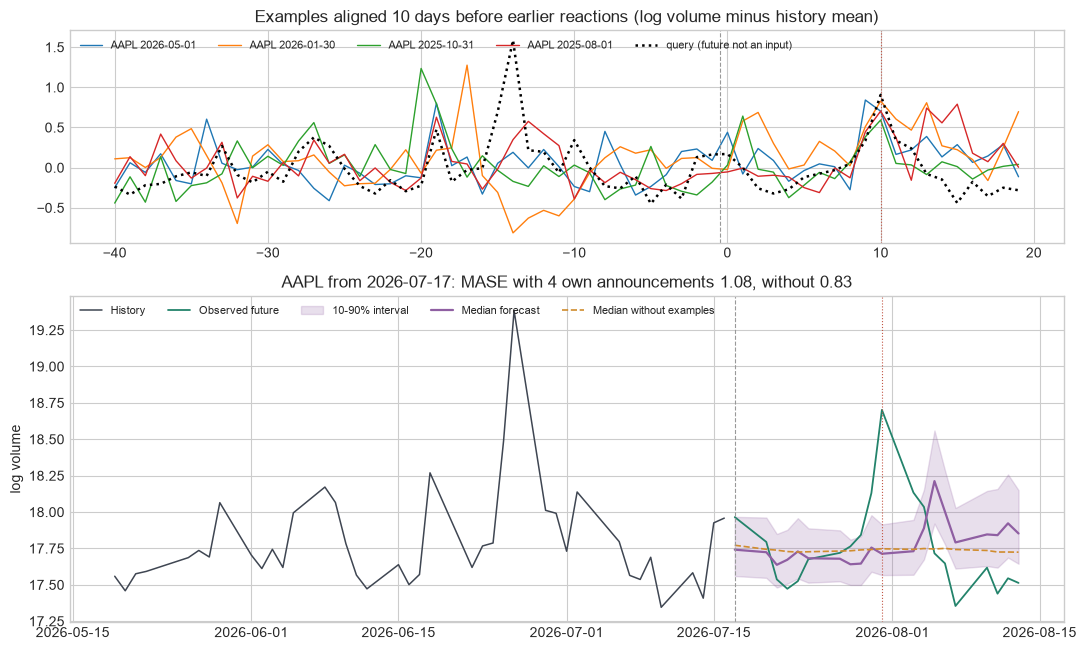

In [16]:
HERO_LEAD = 10
def eligible_reactions(row):
    return [d for d in reaction_days[row] if d - HERO_LEAD + HORIZON <= len(days) and len(aligned_windows(row, d - HERO_LEAD, HERO_LEAD, 4)) == 4]

hero_row = next(r for r in rows + list(range(len(tickers))) if eligible_reactions(r))
hero_origin = eligible_reactions(hero_row)[-1] - HERO_LEAD
hero_sources = aligned_windows(hero_row, hero_origin, HERO_LEAD, 4)
example_q, zero_q = predict([make_example_input(hero_row, hero_origin, hero_sources), make_example_input(hero_row, hero_origin, [])], HORIZON)
hero_future = days[hero_origin:hero_origin + HORIZON]

fig, axes = plt.subplots(2, 1, figsize=(11, 6.6), gridspec_kw={"height_ratios": [1.3, 2.0]})
for r, e in hero_sources:
    window = log_volume[r, e - ICL_CONTEXT:e + HORIZON]
    axes[0].plot(np.arange(-ICL_CONTEXT, HORIZON), window - window[:ICL_CONTEXT].mean(), lw=1.0, label=f"{tickers[r]} {days[e + HERO_LEAD].date()}")
query_window = log_volume[hero_row, hero_origin - ICL_CONTEXT:hero_origin + HORIZON]
axes[0].plot(np.arange(-ICL_CONTEXT, HORIZON), query_window - query_window[:ICL_CONTEXT].mean(), color="black", lw=1.8, ls=":", label="query (future not an input)")
axes[0].axvline(-0.5, color="#999999", lw=0.8, ls="--")
axes[0].axvline(HERO_LEAD, color="#c25645", lw=0.8, ls=":")
axes[0].set_title(f"Examples aligned {HERO_LEAD} days before earlier reactions (log volume minus history mean)")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plot_forecast(axes[1], days[hero_origin - ICL_CONTEXT:hero_origin], log_volume[hero_row, hero_origin - ICL_CONTEXT:hero_origin], hero_future,
              log_volume[hero_row, hero_origin:hero_origin + HORIZON], example_q,
              f"{tickers[hero_row]} from {days[hero_origin].date()}: MASE with 4 own announcements {icl_score(hero_row, hero_origin, example_q[:, 1]):.2f}, "
              f"without {icl_score(hero_row, hero_origin, zero_q[:, 1]):.2f}",
              reference=zero_q[:, 1], reference_label="Median without examples", ylabel="log volume")
axes[1].axvline(days[hero_origin + HERO_LEAD], color="#c25645", lw=0.8, ls=":")
axes[1].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "04a_event_examples")
plt.show()

### 4b. Prompt anatomy: what the model actually sees

The same input as 4a: four completed examples (history → observed future), then the query (history → **?**). The red dotted line marks the earnings reaction in every block.

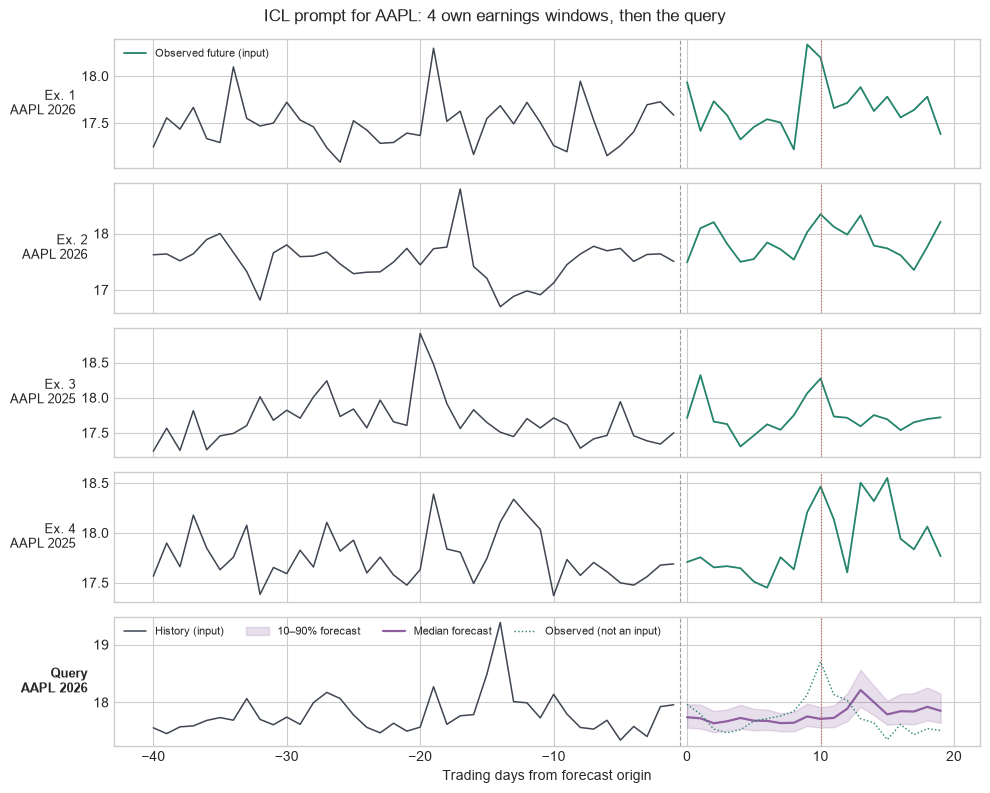

In [17]:
def plot_prompt_anatomy(row, o, sources, quantiles, title, lead, name=None, context=ICL_CONTEXT, example_context=None):
    example_context = example_context or context
    n_rows = len(sources) + 1
    fig, axes = plt.subplots(n_rows, 1, figsize=(10, 1.45 * n_rows + 0.8), sharex=True)
    future_x = np.arange(0, HORIZON)
    for k, (ax, (r, e)) in enumerate(zip(axes, sources)):
        ax.plot(np.arange(-example_context, 0), log_volume[r, e - example_context:e], color=COLORS["history"], lw=1.1)
        ax.plot(future_x, log_volume[r, e:e + HORIZON], color=COLORS["truth"], lw=1.3)
        ax.set_ylabel(f"Ex. {k + 1}\n{tickers[r]} {days[e].year}", rotation=0, ha="right", va="center", fontsize=9)
    ax = axes[-1]
    ax.plot(np.arange(-context, 0), log_volume[row, o - context:o], color=COLORS["history"], lw=1.1, label="History (input)")
    ax.fill_between(future_x, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.2, label="10–90% forecast")
    ax.plot(future_x, quantiles[:, 1], color=COLORS["forecast"], lw=1.6, label="Median forecast")
    ax.plot(future_x, log_volume[row, o:o + HORIZON], color=COLORS["truth"], lw=1.0, ls=":", label="Observed (not an input)")
    ax.set_ylabel(f"Query\n{tickers[row]} {days[o].year}", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    ax.legend(ncol=4, frameon=False, loc="upper left", fontsize=8)
    ax.set_xlabel("Trading days from forecast origin")
    for ax in axes:
        ax.axvline(-0.5, color="#999999", lw=0.8, ls="--")
        ax.axvline(lead, color="#c25645", lw=0.8, ls=":")
    axes[0].plot([], [], color=COLORS["truth"], lw=1.3, label="Observed future (input)")
    axes[0].legend(frameon=False, loc="upper left", fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()

plot_prompt_anatomy(hero_row, hero_origin, hero_sources, example_q,
                    f"ICL prompt for {tickers[hero_row]}: 4 own earnings windows, then the query", HERO_LEAD, name="04b_prompt_anatomy")

### 4c. Scorecard: do examples help, and which ones?

256 event queries (or as many as qualify). Variants:

- zero-shot from the same 40 days (the **reference**),
- 1 and 4 examples from the stock's own earlier announcements,
- 2 own + 3 industry-peer announcements,
- 5 industry-peer announcements only,
- 5 **non-aligned** windows from the stock's own history (same amount of data, random timing relative to earnings),
- **control**: the 2 own + 3 peer examples with their futures rotated, so every history is paired with another example's future.

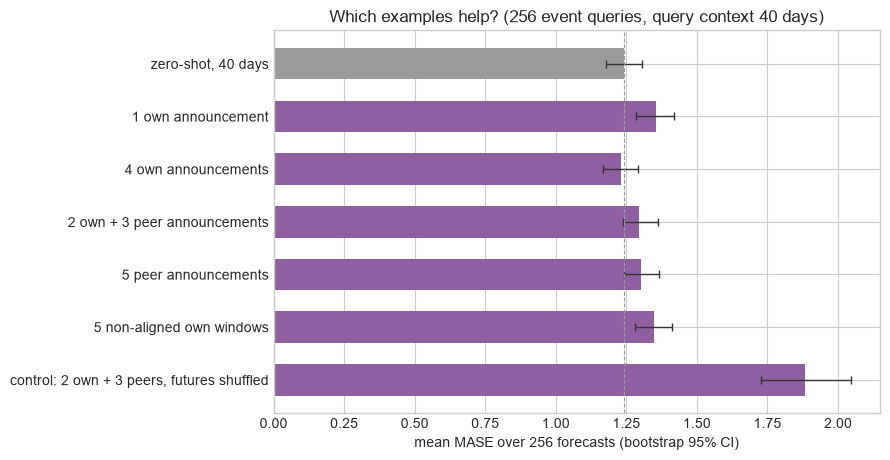

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 40 days",,,,,,
"zero-shot, 40 days",1.240,"[1.176, 1.304]",1.103,NaN,0.000,"[0.000, 0.000]"
1 own announcement,1.353,"[1.283, 1.418]",1.218,0.340,0.113,"[0.071, 0.156]"
4 own announcements,1.230,"[1.169, 1.291]",1.106,0.500,-0.010,"[-0.047, 0.027]"
2 own + 3 peer announcements,1.296,"[1.236, 1.362]",1.160,0.418,0.056,"[0.017, 0.097]"
5 peer announcements,1.302,"[1.243, 1.365]",1.147,0.473,0.062,"[0.018, 0.107]"
5 non-aligned own windows,1.348,"[1.280, 1.411]",1.218,0.336,0.108,"[0.066, 0.146]"
"control: 2 own + 3 peers, futures shuffled",1.884,"[1.728, 2.046]",1.481,0.277,0.644,"[0.498, 0.800]"


In [18]:
def run_variants(queries, variants, context=ICL_CONTEXT):
    return pd.DataFrame({
        name: [icl_score(r, o, q[:, 1], context) for (r, o, _), q in zip(queries, predict([build(r, o, lead) for r, o, lead in queries], HORIZON))]
        for name, build in variants.items()
    })

def own_and_peers(r, o, lead, own=2, peer=3):
    return aligned_windows(r, o, lead, own) + peer_windows(r, o, lead, peer)

ICL_VARIANTS = {
    "zero-shot, 40 days": lambda r, o, lead: make_example_input(r, o, []),
    "1 own announcement": lambda r, o, lead: make_example_input(r, o, aligned_windows(r, o, lead, 1)),
    "4 own announcements": lambda r, o, lead: make_example_input(r, o, aligned_windows(r, o, lead, 4)),
    "2 own + 3 peer announcements": lambda r, o, lead: make_example_input(r, o, own_and_peers(r, o, lead)),
    "5 peer announcements": lambda r, o, lead: make_example_input(r, o, peer_windows(r, o, lead, 5)),
    "5 non-aligned own windows": lambda r, o, lead: make_example_input(r, o, random_windows(r, o, 5)),
    "control: 2 own + 3 peers, futures shuffled": lambda r, o, lead: make_example_input(r, o, own_and_peers(r, o, lead), shuffle_futures=True),
}
REFERENCE = "zero-shot, 40 days"
icl_results = run_variants(event_queries, ICL_VARIANTS)
plot_ladder(icl_results, REFERENCE, f"Which examples help? ({len(icl_results)} event queries, query context 40 days)", name="04c_relevance_ladder")
scorecard(icl_results, reference=REFERENCE)

### 4d. Cold start: 20 days of history, peers only

A newly listed stock (or one after a spin-off or ticker change) has a few weeks of trading history and no earnings history of its own. Its industry peers do.

- **Query**: the last `COLD_CONTEXT = 20` trading days of the event queries above.
- **Examples**: 5 industry-peer announcements aligned at the same lead, each with a 20-day history; the stock's own past is **not** used.

The dataset contains only current index members, so true IPOs are rare; the scorecard therefore simulates the cold start on mature stocks by truncating their history. The real late entrants are listed below for reference.

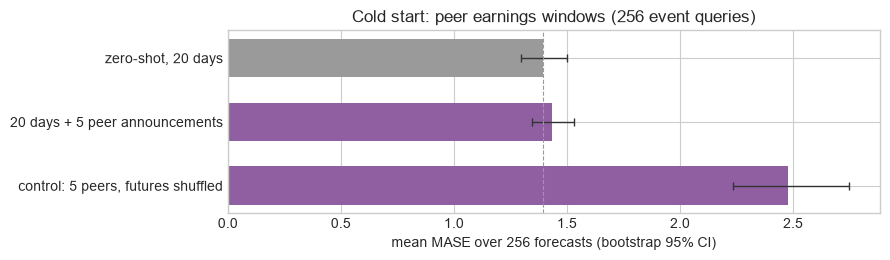

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 20 days",,,,,,
"zero-shot, 20 days",1.393,"[1.298, 1.499]",1.224,NaN,0.000,"[0.000, 0.000]"
20 days + 5 peer announcements,1.435,"[1.344, 1.532]",1.242,0.512,0.042,"[-0.019, 0.107]"
"control: 5 peers, futures shuffled",2.478,"[2.236, 2.747]",1.811,0.250,1.085,"[0.866, 1.341]"


Late entrants (first trading day after 2016-01-02): 35


,id,sector,industry,first_valid
26,PLTR,Information Technology,Application Software,2020-09-30
9,DASH,Consumer Discretionary,Specialized Consumer Services,2020-12-09
0,ABNB,Consumer Discretionary,"Hotels, Resorts & Cruise Lines",2020-12-10
13,EXE,Energy,Oil & Gas Exploration & Production,2021-02-10
5,COIN,Financials,Financial Exchanges & Data,2021-04-14
1,APP,Communication Services,Advertising,2021-04-15
19,HOOD,Financials,Investment Banking & Brokerage,2021-07-29
4,CEG,Utilities,Electric Utilities,2022-01-19
17,GEHC,Health Care,Health Care Equipment,2022-12-15
23,KVUE,Consumer Staples,Personal Care Products,2023-05-04


In [19]:
COLD_CONTEXT = 20
cold_results = run_variants(event_queries, {
    "zero-shot, 20 days": lambda r, o, lead: make_example_input(r, o, [], context=COLD_CONTEXT),
    "20 days + 5 peer announcements": lambda r, o, lead: make_example_input(r, o, peer_windows(r, o, lead, 5, context=COLD_CONTEXT), context=COLD_CONTEXT),
    "control: 5 peers, futures shuffled": lambda r, o, lead: make_example_input(r, o, peer_windows(r, o, lead, 5, context=COLD_CONTEXT), context=COLD_CONTEXT, shuffle_futures=True),
}, context=COLD_CONTEXT)
plot_ladder(cold_results, "zero-shot, 20 days", f"Cold start: peer earnings windows ({len(cold_results)} event queries)", name="04d_cold_start_ladder")
display(scorecard(cold_results, reference="zero-shot, 20 days"))
print(f"Late entrants (first trading day after {complete_from.date()}): {len(late_items)}")
late_items[["id", "sector", "industry", "first_valid"]].sort_values("first_valid").tail(15)

### 4e. Error vs. number of examples

The k-shot curve on the same event queries: the stock's own earlier announcements first (up to 4), then industry peers' most recent announcements, for `k = 0, 1, 2, 3, 4, 6, 8, 10, 12`. Queries without enough peers use as many as are available. The checkpoint was trained with up to 6 examples; the shaded region (`k > 6`) is beyond that.

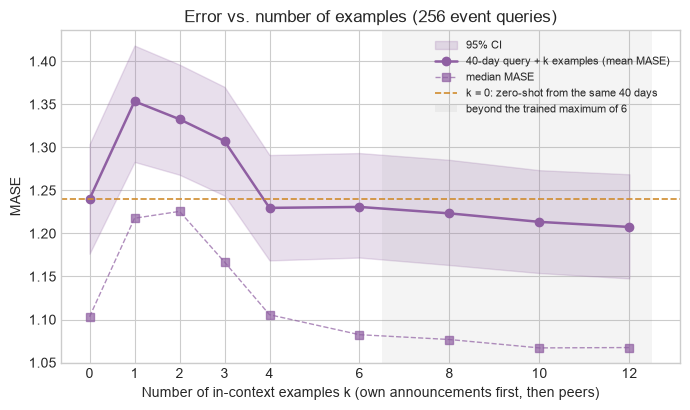

          k=0    k=1    k=2    k=3    k=4    k=6    k=8   k=10   k=12
mean    1.240  1.353  1.333  1.307  1.230  1.231  1.223  1.213  1.208
median  1.103  1.218  1.226  1.167  1.106  1.082  1.077  1.067  1.067


In [20]:
EXAMPLE_COUNTS = [0, 1, 2, 3, 4, 6, 8, 10, 12]
TRAINED_MAX_EXAMPLES = 6

def k_sources(r, o, lead, k):
    return (aligned_windows(r, o, lead, 4) + peer_windows(r, o, lead, 12))[:k]

curve_scores = run_variants(event_queries, {f"k={k}": (lambda k: lambda r, o, lead: make_example_input(r, o, k_sources(r, o, lead, k)))(k) for k in EXAMPLE_COUNTS})
idx = np.random.default_rng(0).integers(0, len(curve_scores), size=(2000, len(curve_scores)))
curve_mean = curve_scores.mean()
curve_ci = np.stack([np.percentile(curve_scores[c].to_numpy()[idx].mean(axis=1), [2.5, 97.5]) for c in curve_scores.columns])

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.fill_between(EXAMPLE_COUNTS, curve_ci[:, 0], curve_ci[:, 1], color=COLORS["forecast"], alpha=0.2, label="95% CI")
ax.plot(EXAMPLE_COUNTS, curve_mean, "o-", color=COLORS["forecast"], lw=1.8, label="40-day query + k examples (mean MASE)")
ax.plot(EXAMPLE_COUNTS, curve_scores.median(), "s--", color=COLORS["forecast"], lw=1.0, alpha=0.7, label="median MASE")
ax.axhline(curve_mean.iloc[0], color=COLORS["reference"], lw=1.2, ls="--", label="k = 0: zero-shot from the same 40 days")
ax.axvspan(TRAINED_MAX_EXAMPLES + 0.5, EXAMPLE_COUNTS[-1] + 0.5, color="#999999", alpha=0.10, lw=0, label="beyond the trained maximum of 6")
ax.set_xticks(EXAMPLE_COUNTS)
ax.set_xlabel("Number of in-context examples k (own announcements first, then peers)")
ax.set_ylabel("MASE")
ax.set_title(f"Error vs. number of examples ({len(curve_scores)} event queries)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
savefig(fig, "04e_example_count_curve")
plt.show()
print(pd.DataFrame({"mean": curve_mean, "median": curve_scores.median()}).round(3).T.to_string())

## Summary

| § | What was shown | Reference |
|---|---|---|
| 1 | Zero-shot 20-day forecasts of log volume and realised volatility; returns as a sanity check | random walk, 20-day mean, seasonal naive |
| 2 | Joint forecasts within a stock and across stocks grouped by GICS industry or k-means, against random groups | each series alone |
| 3 | Market and earnings calendars as known covariates, market/macro series as past-only covariates; earnings-date scenarios; earnings-surprise dose–response | without covariates; pooled historical regression |
| 4 | Event-aligned examples from the stock's own and its peers' earnings; non-aligned and shuffled-futures controls; cold start; k-shot curve | zero-shot from the same short context |

Caveats: the universe is today's S&P 500 members (survivorship bias); earnings timing comes from Yahoo's timestamps where available, and `earnings_window` covers the remaining ±1-day uncertainty; Section 4 does not pass covariates inside examples, because in the Walmart demo doing so made the model ignore the query's own covariates.

## Checkpoint scope

This notebook uses the publicly available forecasting checkpoint. iAmTime also supports imputation, anomaly detection, and classification, but checkpoints for those tasks are not currently published.